<a href="https://colab.research.google.com/github/SJ174/MLCW/blob/main/MLCW_Task_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('/content/WA_Fn-UseC_-Telco-Customer-Churn.csv')

## 1. Dataset Structure and Data Types

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
print("Number of customers:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of customers: 7043
Number of columns: 21


In [5]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [7]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [10]:
(df['TotalCharges'].astype(str).str.strip() == '').sum()

np.int64(11)

## 2. Data Quality and Missing Value Investigation

In [11]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [12]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [13]:
df[df['TotalCharges'].isnull()][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


The initial inspection identified no missing values using pandas' standard null-value check. However, further investigation revealed 11 empty strings in the TotalCharges column. The column was initially stored as an object data type, so the values were converted to a numerical format using pd.to_numeric(). The empty strings were then represented as missing numerical values (NaN), allowing them to be identified through a standard missing-value check. No completely duplicated rows were detected in the dataset.

Further examination revealed that all 11 affected customers had a tenure of zero months and a churn status of "No". This suggests that these customers were new subscribers for whom total charges had not yet been recorded. However, this explanation cannot be confirmed from the dataset alone.

## 3. Exploratory Analysis of Customer Churn

In [14]:
df['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


In [15]:
churn_counts = df['Churn'].value_counts()
churn_percentages = df['Churn'].value_counts(normalize=True) * 100

print("Customer counts:")
print(churn_counts)

print("\nCustomer percentages:")
print(churn_percentages.round(2))

Customer counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Customer percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


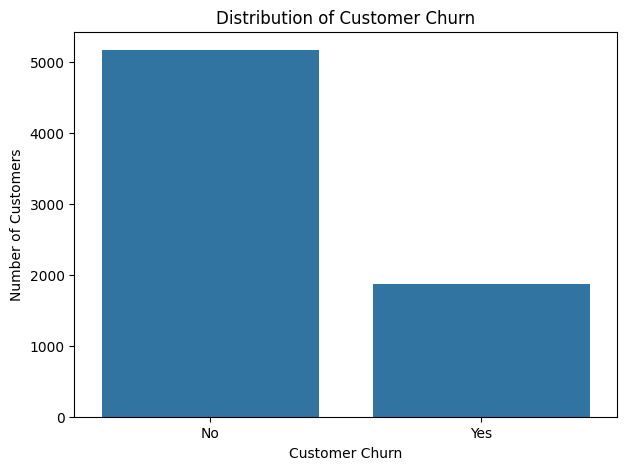

In [16]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='Churn')

plt.title('Distribution of Customer Churn')
plt.xlabel('Customer Churn')
plt.ylabel('Number of Customers')

plt.show()

The dataset contains 7,043 customer records, of which 5,174 customers (73.46%) remained with the company, while 1,869 customers (26.54%) churned. The bar chart illustrates the distribution of the target variable, Churn. It shows that the majority of customers remained with the company, while approximately one-quarter discontinued their services.

The difference between the two categories indicates that the target variable is imbalanced, with the non-churn category containing more observations than the churn category. This is an important consideration when developing and evaluating machine learning classification models, as accuracy alone may not reflect a model's ability to identify customers who churn. Therefore, additional evaluation metrics, such as precision, recall, F1-score, and the confusion matrix, should be considered when assessing model performance.

This analysis establishes the baseline distribution of customer churn and provides a foundation for investigating relationships between customer characteristics and churn in subsequent analyses.

## 4. Relationship Between Customer Tenure and Churn

In [17]:
df.groupby('Churn')['tenure'].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,37.569965,24.113777,0.0,15.0,38.0,61.0,72.0
Yes,1869.0,17.979133,19.531123,1.0,2.0,10.0,29.0,72.0


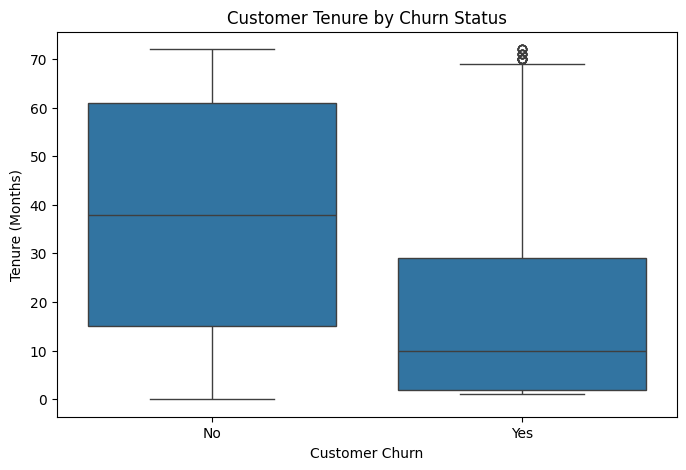

In [18]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='Churn', y='tenure')

plt.title('Customer Tenure by Churn Status')
plt.xlabel('Customer Churn')
plt.ylabel('Tenure (Months)')

plt.show()

The relationship between customer tenure and churn was investigated using descriptive statistics and a box plot. Customers who remained with the company had a mean tenure of
37.57 months and a median tenure of 38 months. In comparison, customers who churned had a mean tenure of 17.98 months and a median tenure of 10 months.

The box plot further displays this difference, with the median tenure of customers who churned considerably lower than that of customers who stayed. The middle 50% of churned customers had tenures between 2 and 29 months, whereas the corresponding range for customers who remained was between 15 and 61 months.

These findings suggest an association between shorter customer tenure and churn. However, the distributions overlap, indicating that tenure alone cannot completely distinguish customers who churn from those who remain. Several potential outliers were also observed among customers who churned, representing individuals with relatively long tenures. Overall, tenure appears to be a potentially useful feature for predicting customer churn.

## 5. Relationship Between Contract Type and Churn

In [19]:
df['Contract'].value_counts()

,count
Contract,
Month-to-month,3875
Two year,1695
One year,1473


In [20]:
contract_churn = pd.crosstab(
    df['Contract'],
    df['Churn'],
    normalize='index'
) * 100

contract_churn.round(2)

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


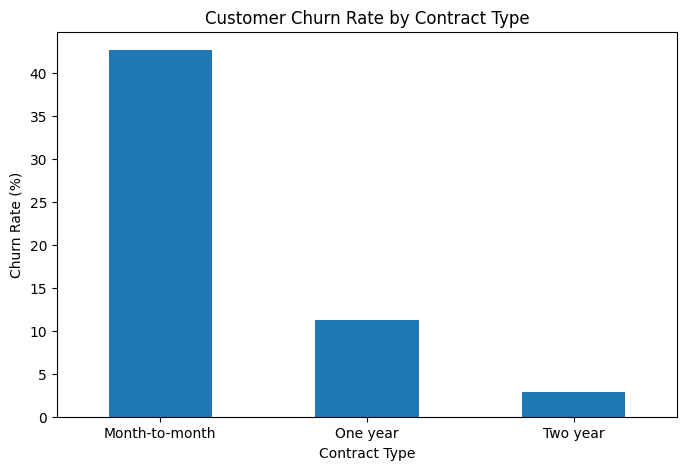

In [21]:
contract_churn['Yes'].plot(kind='bar', figsize=(8, 5))

plt.title('Customer Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)

plt.show()

The relationship between contract type and customer churn was investigated by calculating the churn rate for each contract category and visualising the results using a bar chart. The results show that customers with month-to-month contracts had the highest churn rate, at 42.71%. In comparison, customers with one-year contracts had a churn rate of 11.27%, while those with two-year contracts had the lowest churn rate of 2.83%.

These findings indicate a substantial difference in churn rates across contract types. Customers with month-to-month contracts were considerably more likely to churn than customers with longer-term contracts in this dataset. The results suggest that contract type may be an important feature for predicting customer churn.

From a business perspective, these findings could help the company identify customer groups that may benefit from targeted retention strategies. However, the analysis establishes an association rather than causation. Other factors, such as customer tenure, pricing and service experiences, may also contribute to the observed differences.

## 6. Relationship Between Monthly Charges and Churn

In [22]:
df.groupby('Churn')['MonthlyCharges'].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,61.265124,31.092648,18.25,25.10,64.425,88.4,118.75
Yes,1869.0,74.441332,24.666053,18.85,56.15,79.650,94.2,118.35


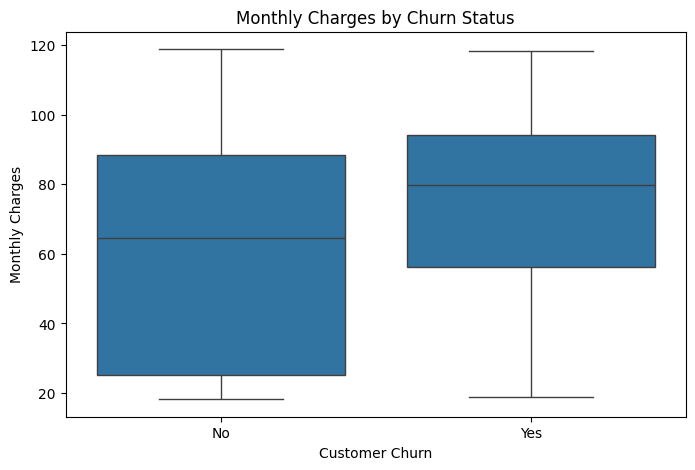

In [23]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Churn', y='MonthlyCharges')

plt.title('Monthly Charges by Churn Status')
plt.xlabel('Customer Churn')
plt.ylabel('Monthly Charges')

plt.show()

The relationship between monthly charges and customer churn was investigated using descriptive statistics and a box plot. Customers who remained with the company had a mean monthly charge of 61.27 and a median of 64.43. In comparison, customers who churned had a mean monthly charge of 74.44 and a median of 79.65.

The results indicate that customers who churned generally had higher monthly charges than those who remained. This pattern is also visible in the box plot, where the median monthly charge for the churn group is higher than that of the non-churn group. However, the distributions overlap, indicating that monthly charges alone cannot fully distinguish between customers who churn and those who stay. Other customer characteristics may also be associated with churn.

Overall, monthly charges appear to be a potentially useful feature for predicting customer churn. However, the observed relationship does not establish that higher monthly charges directly cause customers to leave.

## 7. Relationship Between Internet Service and Churn

In [24]:
df['InternetService'].value_counts()

,count
InternetService,
Fiber optic,3096
DSL,2421
No,1526


In [25]:
internet_churn = pd.crosstab(
    df['InternetService'],
    df['Churn'],
    normalize='index'
) * 100

internet_churn.round(2)

Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


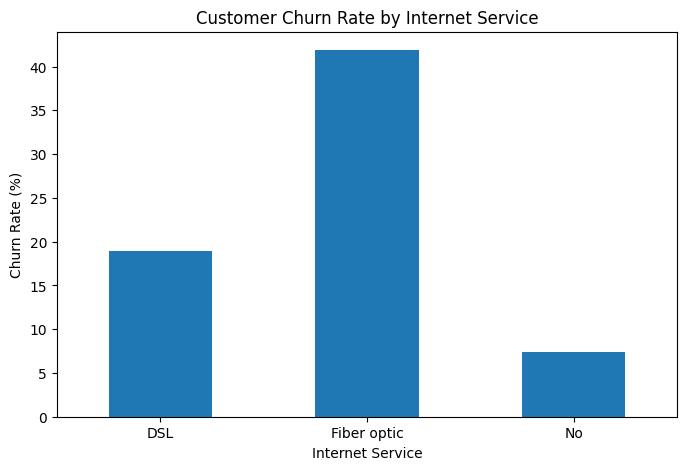

In [26]:
internet_churn['Yes'].plot(kind='bar', figsize=(8, 5))

plt.title('Customer Churn Rate by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)

plt.show()

The relationship between internet service type and customer churn was investigated by calculating the churn rate for each category and visualising the results using a bar chart. The results show that Fiber optic customers had the highest churn rate, at 41.89%. In comparison, customers using DSL had a churn rate of 18.96%, while customers without internet service had the lowest churn rate, at 7.40%. The difference between Fiber optic and DSL customers was 22.93 percentage points, indicating a substantial variation in churn rates between these categories. The bar chart clearly illustrates this pattern, with Fiber optic having the highest bar and the category without internet service having the lowest.

These findings suggest that internet service type is associated with customer churn and may be a useful feature for predicting churn. From a business perspective, the company could investigate why Fiber optic customers have a higher churn rate and whether factors such as pricing, service quality or customer experience contribute to this pattern. However, this analysis does not establish that internet service type directly causes customers to churn. Other customer characteristics may also influence the observed differences.

## 8. Relationship Between Online Security and Churn

In [27]:
df['OnlineSecurity'].value_counts()

,count
OnlineSecurity,
No,3498
Yes,2019
No internet service,1526


In [28]:
security_churn = pd.crosstab(
    df['OnlineSecurity'],
    df['Churn'],
    normalize='index'
) * 100

security_churn.round(2)

Churn,No,Yes
OnlineSecurity,,
No,58.23,41.77
No internet service,92.60,7.40
Yes,85.39,14.61


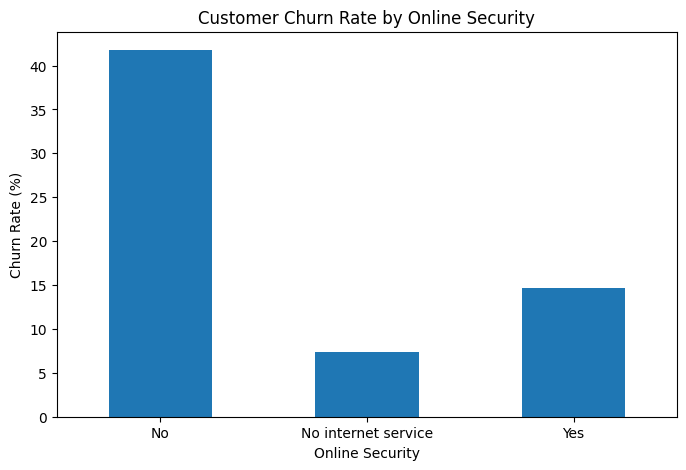

In [29]:
security_churn['Yes'].plot(kind='bar', figsize=(8, 5))

plt.title('Customer Churn Rate by Online Security')
plt.xlabel('Online Security')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)

plt.show()

The relationship between online security and customer churn was investigated by calculating the churn rate for each category and visualising the results using a bar chart. The results indicate that customers without online security had the highest churn rate, at 41.77%. In comparison, customers who subscribed to online security had a churn rate of 14.61%. Customers without internet service had the lowest churn rate, at 7.40%. The difference between customers without online security and those with online security was 27.16 percentage points. This indicates a substantial difference in the observed churn rates between these two groups.

These findings suggest that online security status is associated with customer churn and may be a useful feature for predicting churn. From a business perspective, the company could investigate the needs and experiences of customers who do not subscribe to online security to identify potential opportunities for improving customer retention. However, this analysis does not establish that subscribing to online security directly reduces churn. Other factors, including contract type, customer tenure and monthly charges, may also contribute to the observed differences.

## 9. Relationship Between Technical Support and Churn

In [30]:
df['TechSupport'].value_counts()

,count
TechSupport,
No,3473
Yes,2044
No internet service,1526


In [31]:
techsupport_churn = pd.crosstab(
    df['TechSupport'],
    df['Churn'],
    normalize='index'
) * 100
techsupport_churn.round(2)

Churn,No,Yes
TechSupport,,
No,58.36,41.64
No internet service,92.60,7.40
Yes,84.83,15.17


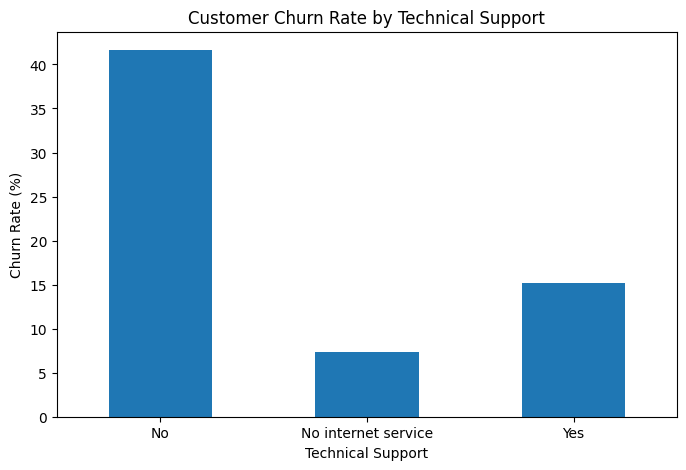

In [32]:
techsupport_churn['Yes'].plot(kind='bar', figsize=(8, 5))

plt.title('Customer Churn Rate by Technical Support')
plt.xlabel('Technical Support')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)

plt.show()

The relationship between technical support and customer churn was investigated by calculating the churn rate for each category and visualising the results using a bar chart. The results indicate that customers without technical support had the highest churn rate, at 41.64%. In comparison, customers who subscribed to technical support had a churn rate of 15.17%. Customers without internet service had the lowest churn rate, at 7.40%. The difference between customers without technical support and those with technical support was 26.47 percentage points. This indicates a substantial difference in the observed churn rates between these groups.

These findings suggest that technical support status is associated with customer churn and may be a useful feature for predicting churn. From a business perspective, the company could investigate whether customers without technical support experience difficulties that contribute to dissatisfaction or whether other customer characteristics explain the observed pattern. However, this analysis does not establish that subscribing to technical support directly reduces churn. Other factors, including contract type, tenure and monthly charges, may also influence the observed differences.

## 10. Combined Relationship Between Online Security, Technical Support and Churn

In [33]:
security_support_churn = pd.crosstab(
    [df['OnlineSecurity'], df['TechSupport']],
    df['Churn'],
    normalize='index'
) * 100

security_support_churn.round(2)

Churn                                       No    Yes
OnlineSecurity      TechSupport                      
No                  No                   51.04  48.96
                    Yes                  77.67  22.33
No internet service No internet service  92.60   7.40
Yes                 No                   78.70  21.30
                    Yes                  90.99   9.01

The analysis indicates that customer churn rates vary considerably depending on the combination of online security and technical support services. Customers without either service have the highest churn rate of 48.96%, while customers who have both services have a substantially lower churn rate of 9.01%. Customers who have only technical support or only online security have churn rates of 22.33% and 21.30%, respectively.

These findings suggest that the availability of online security and technical support services is associated with customer retention. Customers who have access to both services may be less likely to churn than those who have neither service. Therefore, online security and technical support may be useful features to consider when developing a customer churn prediction model.

## 11. Relationship between payment method and churn

In [34]:
df['PaymentMethod'].value_counts()

,count
PaymentMethod,
Electronic check,2365
Mailed check,1612
Bank transfer (automatic),1544
Credit card (automatic),1522


In [35]:
payment_churn = pd.crosstab(
    df['PaymentMethod'],
    df['Churn'],
    normalize='index'
) * 100

payment_churn.round(2)

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


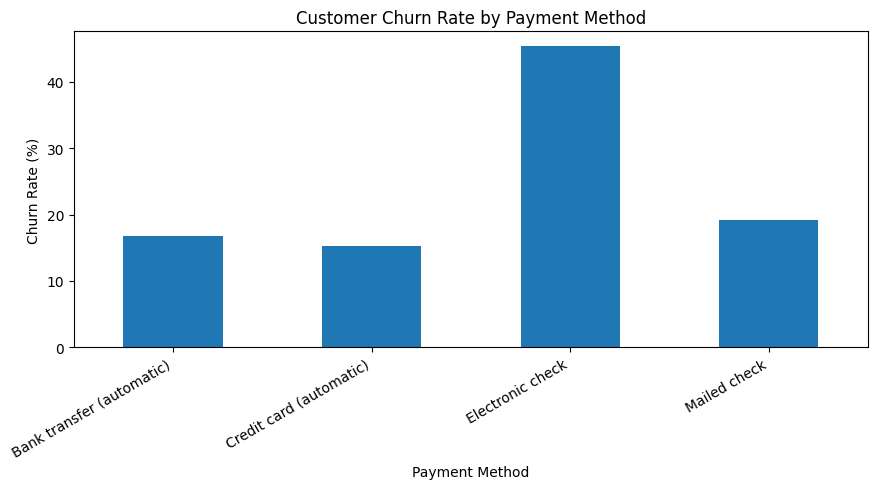

In [36]:
payment_churn['Yes'].plot(kind='bar', figsize=(9, 5))

plt.title('Customer Churn Rate by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=30, ha='right')

plt.tight_layout()
plt.show()

The analysis shows that customer churn rates differ considerably across payment methods. Customers who use electronic checks have the highest churn rate at 45.29%, compared with 19.11% for mailed checks, 16.71% for automatic bank transfers, and 15.24% for automatic credit card payments.

Customers using automatic payment methods have comparatively lower churn rates than those using electronic checks. This suggests that payment method may be associated with customer retention and could provide useful information for predicting churn. However, these findings do not establish that electronic checks cause customers to leave. Payment method may be associated with other factors, such as contract type, tenure, or customer characteristics.

## 12. Relationship Between Partner Status and Churn

In [37]:
df['Partner'].value_counts()

,count
Partner,
No,3641
Yes,3402


In [38]:
partner_churn = pd.crosstab(
    df['Partner'],
    df['Churn'],
    normalize='index'
) * 100

partner_churn.round(2)

Churn,No,Yes
Partner,,
No,67.04,32.96
Yes,80.34,19.66


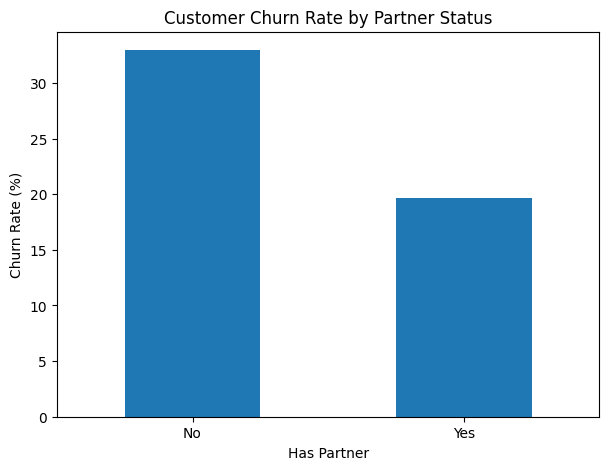

In [39]:
partner_churn['Yes'].plot(kind='bar', figsize=(7, 5))

plt.title('Customer Churn Rate by Partner Status')
plt.xlabel('Has Partner')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)

plt.show()

The analysis reveals a noticeable relationship between partner status and customer churn. Customers without partners have a churn rate of 32.96%, compared with 19.66% for customers who have partners. This represents a difference of 13.30 percentage points.

These findings suggest that customers without partners may be at a higher risk of churning than customers with partners. However, this relationship does not establish causation, as other customer characteristics may also influence churn behaviour.

## 13. Relationship Between dependent status and Churn

In [40]:
df['Dependents'].value_counts()

,count
Dependents,
No,4933
Yes,2110


In [41]:
dependents_churn = pd.crosstab(
    df['Dependents'],
    df['Churn'],
    normalize='index'
) * 100

dependents_churn.round(2)

Churn,No,Yes
Dependents,,
No,68.72,31.28
Yes,84.55,15.45


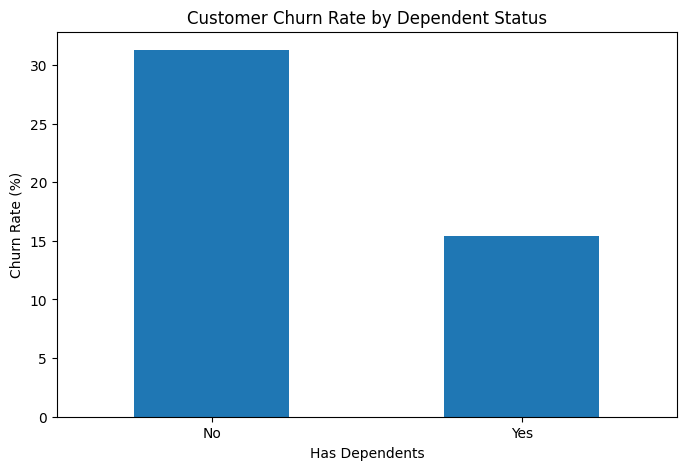

In [42]:
dependents_churn['Yes'].plot(kind='bar', figsize=(8, 5))

plt.title('Customer Churn Rate by Dependent Status')
plt.xlabel('Has Dependents')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)

plt.show()

The analysis reveals a noticeable relationship between dependent status and customer churn. Customers without dependents have a churn rate of 31.28%, compared with 15.45% among customers with dependents. This represents a difference of 15.83 percentage points.

These findings suggest that customers without dependents may be more likely to discontinue their services than customers with dependents. Household circumstances may be associated with customer retention, although further analysis would be required to investigate this relationship more thoroughly. The observed association does not establish causation.

## 14. Relationship Between Paperless Billing and Churn

In [43]:
df['PaperlessBilling'].value_counts()

,count
PaperlessBilling,
Yes,4171
No,2872


In [44]:
paperless_churn = pd.crosstab(
    df['PaperlessBilling'],
    df['Churn'],
    normalize='index'
) * 100

paperless_churn.round(2)

Churn,No,Yes
PaperlessBilling,,
No,83.67,16.33
Yes,66.43,33.57


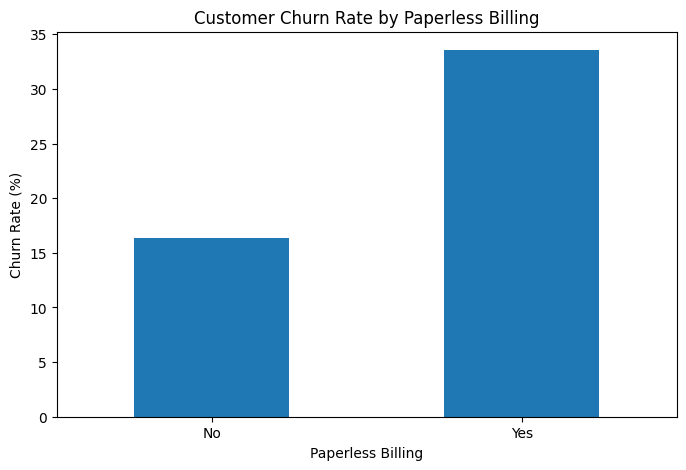

In [45]:
paperless_churn['Yes'].plot(kind='bar', figsize=(8, 5))

plt.title('Customer Churn Rate by Paperless Billing')
plt.xlabel('Paperless Billing')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)

plt.show()

The analysis reveals a noticeable relationship between paperless billing and customer churn. Customers who use paperless billing have a churn rate of 33.57%, compared with 16.33% among customers who do not use paperless billing. This represents a difference of 17.24 percentage points.

These findings suggest that customers using paperless billing are more likely to discontinue their services. However, this association does not establish causation. Other factors, such as contract type, payment method, and customer tenure, may contribute to the observed difference.

## 15. Relationship Between Online Backup and Churn

In [46]:
df['OnlineBackup'].value_counts()

,count
OnlineBackup,
No,3088
Yes,2429
No internet service,1526


In [47]:
backup_churn = pd.crosstab(
    df['OnlineBackup'],
    df['Churn'],
    normalize='index'
) * 100

backup_churn.round(2)

Churn,No,Yes
OnlineBackup,,
No,60.07,39.93
No internet service,92.60,7.40
Yes,78.47,21.53


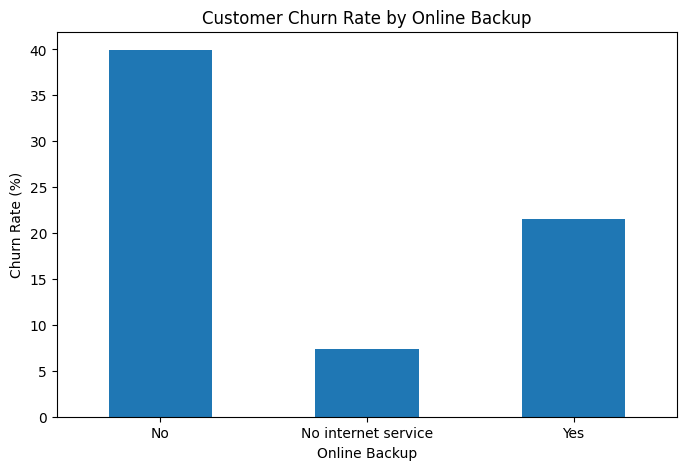

In [48]:
backup_churn['Yes'].plot(kind='bar', figsize=(8, 5))

plt.title('Customer Churn Rate by Online Backup')
plt.xlabel('Online Backup')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)

plt.show()

The analysis reveals a noticeable relationship between online backup subscriptions and customer churn. Customers without online backup have a churn rate of 39.93%, compared with 21.53% among customers who have online backup. This represents a difference of 18.40 percentage points.

Customers without online backup therefore appear more likely to discontinue their services than those who subscribe to online backup. This pattern may be associated with differences in customer engagement, contract type, or tenure. However, further analysis would be required to investigate these possibilities, as the observed association does not establish causation.

## 16. Relationship Between Device Protection and Churn

In [50]:
df['DeviceProtection'].value_counts()

,count
DeviceProtection,
No,3095
Yes,2422
No internet service,1526


In [49]:
device_protection_churn = pd.crosstab(
    df['DeviceProtection'],
    df['Churn'],
    normalize='index'
) * 100

device_protection_churn.round(2)

Churn,No,Yes
DeviceProtection,,
No,60.87,39.13
No internet service,92.60,7.40
Yes,77.50,22.50


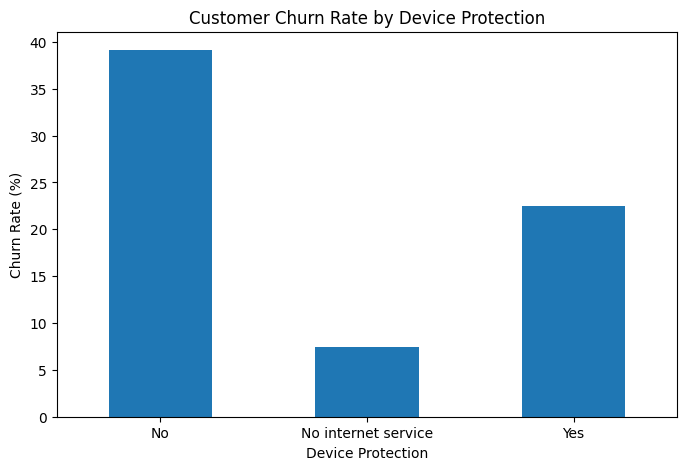

In [51]:
device_protection_churn['Yes'].plot(kind='bar', figsize=(8, 5))

plt.title('Customer Churn Rate by Device Protection')
plt.xlabel('Device Protection')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)

plt.show()

The analysis shows that customers without device protection have a higher churn rate (39.13%) compared to customers who have device protection (22.50%). This indicates that customers who do not subscribe to device protection are more likely to leave the company. However, this relationship does not necessarily imply that the absence of device protection directly causes customer churn.

## 16. Combined Relationship Between Online Security, Technical Support, Online Backup and Churn

In [52]:
service_combination_churn = (
    df.groupby(['OnlineSecurity', 'TechSupport', 'OnlineBackup']).agg(
        Customer_Count=('Churn', 'size'),
        Churn_Rate=('Churn', lambda x: (x == 'Yes').mean() * 100)
    ).reset_index()
)
service_combination_churn = service_combination_churn.sort_values(
    by='Churn_Rate',
    ascending=False
)
service_combination_churn.round(2)

,OnlineSecurity,TechSupport,OnlineBackup,Customer_Count,Churn_Rate
0,No,No,No,1713,54.00
1,No,No,Yes,840,38.69
2,No,Yes,No,482,27.39
5,Yes,No,No,483,25.67
3,No,Yes,Yes,463,17.06
6,Yes,No,Yes,437,16.48
7,Yes,Yes,No,410,12.68
4,No internet service,No internet service,No internet service,1526,7.40
8,Yes,Yes,Yes,689,6.82


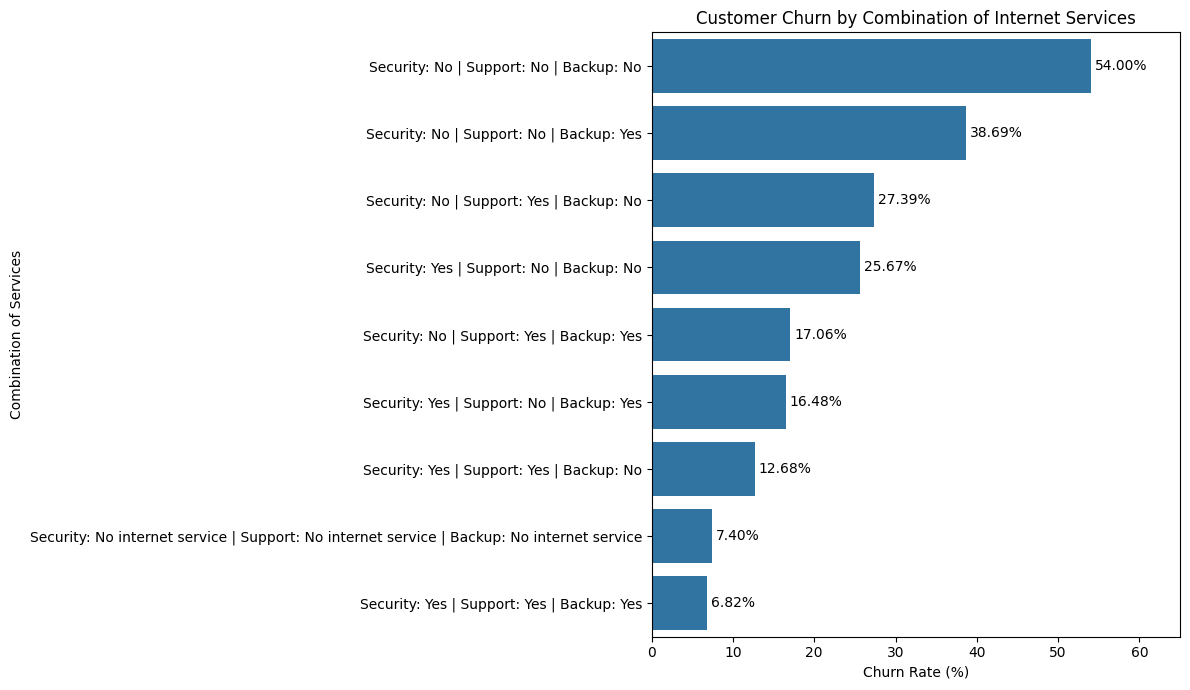

In [55]:
plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=service_combination_churn,
    x='Churn_Rate',
    y='Service_Combination'
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.2f%%',
        padding=3
    )

plt.title('Customer Churn by Combination of Internet Services')
plt.xlabel('Churn Rate (%)')
plt.ylabel('Combination of Services')
plt.xlim(0, 65)

plt.tight_layout()
plt.show()

The analysis shows that customer churn rates vary across combinations of online security, technical support and online backup subscriptions. Customers without any of these three services have the highest churn rate of 54.00%, while customers who subscribe to all three services have a much lower churn rate of 6.82%. Customers with other combinations of services also exhibit different churn rates. Customers without internet service form a separate category, with a churn rate of 7.40%.

Overall, these findings suggest that the combination of internet-related services a customer subscribes to is associated with customer churn. However, these relationships do not establish causation, as other factors, such as contract type, tenure and monthly charges, may also influence churn.